05 · Calibration et seuil de décision

Étapes 8 et 9. Tout est mesuré sur des prédictions hors pli (out-of-fold) du train : le test reste scellé.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from inclusion_financiere.config import RANDOM_STATE, FIGURES, DECISIONS, COST_FP, COST_FN
from inclusion_financiere.data import load_raw, clean, split, make_cv, CAT_COLS, NUM_COLS

FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

import json
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             make_scorer, roc_auc_score)
from sklearn.model_selection import TunedThresholdClassifierCV, cross_val_predict

from inclusion_financiere.features import pipe
from inclusion_financiere.evaluate import cout_total, expected_calibration_error, seuil_theorique

In [2]:
X, y = clean(load_raw())
X_train, X_test, y_train, y_test = split(X, y)
del X_test, y_test  # test sous scellé jusqu'à l'étape 10
cv = make_cv()       # le même objet cv pour tous les modèles
print(X_train.shape, round(y_train.mean(), 4))

dec = json.loads(DECISIONS.read_text())
meilleur_modele = pipe(HistGradientBoostingClassifier(**dec["histgb_params"], random_state=RANDOM_STATE))
foret = pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=dec["rf_min_samples_leaf"],
                                    n_jobs=-1, random_state=RANDOM_STATE))
logreg = pipe(LogisticRegression(max_iter=2000))

(18819, 10) 0.1408


8.1 · Mesurer la calibration

In [3]:
def oof(m):
    return cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

p = {"HistGB réglé": oof(meilleur_modele), "Random Forest": oof(foret), "LogReg": oof(logreg)}


def bilan(probas):
    return pd.DataFrame({n: {"PR-AUC": average_precision_score(y_train, q),
                             "ROC-AUC": roc_auc_score(y_train, q),
                             "Brier": brier_score_loss(y_train, q),
                             "ECE": expected_calibration_error(y_train, q)}
                         for n, q in probas.items()}).T.round(4)

bilan(p)

,PR-AUC,ROC-AUC,Brier,ECE
HistGB réglé,0.5785,0.8607,0.0848,0.0079
Random Forest,0.5642,0.8535,0.0878,0.0205
LogReg,0.5579,0.8489,0.0870,0.0057


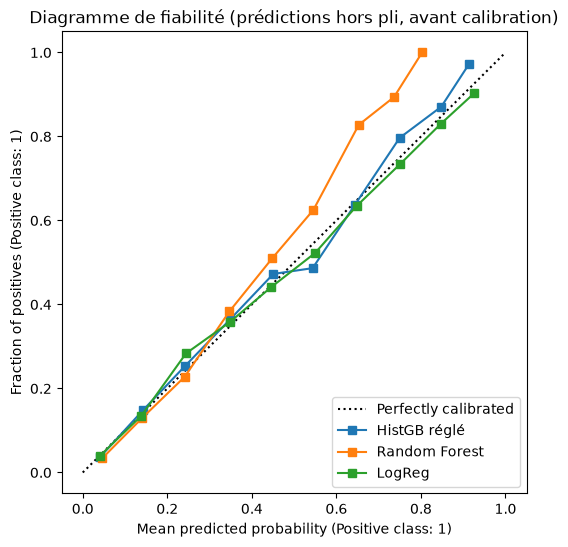

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
for n, q in p.items():
    CalibrationDisplay.from_predictions(y_train, q, n_bins=10, name=n, ax=ax)
ax.set_title("Diagramme de fiabilité (prédictions hors pli, avant calibration)")
plt.savefig(FIGURES / "05_fiabilite_avant.png", dpi=120, bbox_inches="tight"); plt.show()

In [5]:
# Où le modèle se trompe-t-il ? fréquence observée - probabilité moyenne, par intervalle
for n in ("HistGB réglé", "Random Forest"):
    q = p[n]
    b = pd.cut(q, np.linspace(0, 1, 11), include_lowest=True)
    t = pd.DataFrame({"y": y_train.values, "p": q}).groupby(b, observed=True).agg(
        n=("y", "size"), p_moy=("p", "mean"), freq=("y", "mean"))
    t["freq - p"] = t["freq"] - t["p_moy"]
    print(n); print(t.round(3), "\n")

HistGB réglé
                   n  p_moy   freq  freq - p
(-0.001, 0.1]  11865  0.041  0.037    -0.004
(0.1, 0.2]      3082  0.143  0.149     0.006
(0.2, 0.3]      1262  0.242  0.254     0.012
(0.3, 0.4]       816  0.349  0.365     0.016
(0.4, 0.5]       514  0.451  0.473     0.022
(0.5, 0.6]       335  0.544  0.487    -0.057
(0.6, 0.7]       320  0.644  0.638    -0.006
(0.7, 0.8]       310  0.750  0.797     0.047
(0.8, 0.9]       279  0.848  0.871     0.023
(0.9, 1.0]        36  0.914  0.972     0.059 

Random Forest
                   n  p_moy   freq  freq - p
(-0.001, 0.1]  10717  0.047  0.034    -0.012
(0.1, 0.2]      3921  0.141  0.130    -0.011
(0.2, 0.3]      1538  0.241  0.228    -0.013
(0.3, 0.4]      1092  0.347  0.384     0.037
(0.4, 0.5]       704  0.448  0.510     0.062
(0.5, 0.6]       363  0.546  0.625     0.080
(0.6, 0.7]       238  0.653  0.828     0.175
(0.7, 0.8]       245  0.736  0.894     0.158
(0.8, 0.9]         1  0.803  1.000     0.197 



Q8.1 — Avant calibration : HistGB réglé (ECE 0,008), régression logistique (ECE 0,006), forêt (ECE 0,021).
- HistGB : la courbe suit presque la diagonale, les erreurs sont petites (1 à 6 points).
- Forêt : elle surestime les petites probabilités et sous-estime les grandes (elle ne dépasse jamais 0,81). En faisant la moyenne de beaucoup d'arbres, les scores sont tirés vers le milieu.

8.2 · Corriger : Platt et isotone

In [6]:
iso = CalibratedClassifierCV(meilleur_modele, method="isotonic", cv=5)
platt = CalibratedClassifierCV(meilleur_modele, method="sigmoid", cv=5)
p["HistGB + isotone"] = oof(iso)
p["HistGB + Platt"] = oof(platt)
calib = bilan({k: p[k] for k in ("HistGB réglé", "HistGB + isotone", "HistGB + Platt")})
calib

,PR-AUC,ROC-AUC,Brier,ECE
HistGB réglé,0.5785,0.8607,0.0848,0.0079
HistGB + isotone,0.5737,0.8611,0.0850,0.0032
HistGB + Platt,0.5768,0.8611,0.0849,0.0061


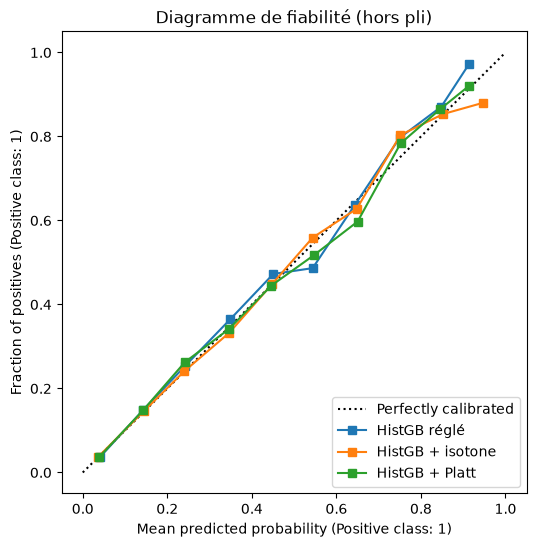

Méthode retenue : sigmoid


In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
for n in ("HistGB réglé", "HistGB + isotone", "HistGB + Platt"):
    CalibrationDisplay.from_predictions(y_train, p[n], n_bins=10, name=n, ax=ax)
ax.set_title("Diagramme de fiabilité (hors pli)")
plt.savefig(FIGURES / "05_fiabilite.png", dpi=120, bbox_inches="tight"); plt.show()

# Choix de la calibration sur le train (hors pli) : le plus petit Brier
methode = "isotonic" if calib.loc["HistGB + isotone", "Brier"] <= calib.loc["HistGB + Platt", "Brier"] else "sigmoid"
cle_cal = "HistGB + isotone" if methode == "isotonic" else "HistGB + Platt"
p_cal = p[cle_cal]
modele_calibre = iso if methode == "isotonic" else platt
print("Méthode retenue :", methode)

Q8.2 —

| HistGB réglé | Brier | ECE | PR-AUC | ROC-AUC |
|---|---|---|---|---|
| sans calibration | 0,0848 | 0,0079 | 0,5785 | 0,8607 |
| + isotone | 0,0850 | 0,0032 | 0,5737 | 0,8611 |
| + Platt (sigmoïde) | 0,0849 | 0,0061 | 0,5768 | 0,8611 |

HistGB était déjà bien calibré, la calibration ne change presque rien. Je garde Platt par sécurité. Pourquoi il est déjà bien calibré : il est entraîné avec la log-loss, qui pousse le modèle à donner les bonnes probabilités.

Q8.3 — Presque pas (ROC-AUC 0,8607 → 0,8611). La calibration change les valeurs des probabilités mais pas l'ordre des personnes, et les AUC dépendent seulement de l'ordre. Les petites différences viennent du réentraînement sur 5 plis dans `CalibratedClassifierCV`.

8.3 · Compter les personnes bancarisées par pays

In [8]:
agg = pd.DataFrame({"pays": X_train["country"], "reel": y_train,
                    **{n: p[n] for n in ("HistGB réglé", cle_cal, "Random Forest", "LogReg")}})
agg = agg.groupby("pays").sum()
erreurs = agg.drop(columns="reel").sub(agg["reel"], axis=0).div(agg["reel"], axis=0) * 100
print("Nombre réel et somme des probabilités :"); print(agg.round(0))
print("\nErreur relative (%) :"); print(erreurs.round(1))
print("\nErreur relative absolue moyenne (%) :"); print(erreurs.abs().mean().round(2))

Nombre réel et somme des probabilités :
          reel  HistGB réglé  HistGB + Platt  Random Forest  LogReg
pays                                                               
Kenya     1207        1190.0          1207.0         1106.0  1206.0
Rwanda     808         794.0           789.0          784.0   808.0
Tanzania   490         502.0           498.0          552.0   490.0
Uganda     145         154.0           154.0          207.0   146.0

Erreur relative (%) :
          HistGB réglé  HistGB + Platt  Random Forest  LogReg
pays                                                         
Kenya             -1.4             0.0           -8.3    -0.1
Rwanda            -1.7            -2.3           -2.9    -0.0
Tanzania           2.4             1.7           12.6     0.0
Uganda             6.1             5.9           42.7     0.9

Erreur relative absolue moyenne (%) :
HistGB réglé       2.90
HistGB + Platt     2.47
Random Forest     16.64
LogReg             0.24
dtype: float64


Q8.4 — Somme des probabilités comparée au vrai nombre de bancarisés :

| Pays | Réel | HistGB | HistGB + Platt | Forêt | LogReg |
|---|---|---|---|---|---|
| Kenya | 1 207 | 1 190 (−1,4 %) | 1 207 (0,0 %) | 1 106 (−8,3 %) | 1 206 (−0,1 %) |
| Rwanda | 808 | 794 (−1,7 %) | 789 (−2,3 %) | 784 (−2,9 %) | 808 (0,0 %) |
| Tanzanie | 490 | 502 (+2,4 %) | 498 (+1,7 %) | 552 (+12,6 %) | 490 (0,0 %) |
| Ouganda | 145 | 154 (+6,1 %) | 154 (+5,9 %) | 207 (+42,7 %) | 146 (+0,9 %) |

Pour compter, la régression logistique est la meilleure (presque 0 % d'erreur). HistGB calibré est bien aussi, la forêt est mauvaise (+43 % en Ouganda). On pourrait utiliser HistGB pour KaziPay et la régression logistique pour la banque centrale.

Q8.5 — La calibration doit être apprise sur des données que le modèle n'a pas vues. Sur les données d'entraînement, le modèle est trop sûr de lui, donc la calibration serait fausse. Sur le test, ce serait tricher : le test ne servirait plus à mesurer honnêtement. `CalibratedClassifierCV(cv=5)` fait ça correctement avec des plis internes.

Étape 9 · Choisir le seuil de décision

In [9]:
t_star = seuil_theorique()


def resume_seuil(q, s, c_fp=COST_FP, c_fn=COST_FN):
    pred = (q >= s).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    return {"seuil": round(s, 4), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "contactés": int(pred.sum()), "coût (USD)": cout_total(y_train, pred, c_fp, c_fn)}

scorer_cout = make_scorer(lambda yt, yp: -cout_total(yt, yp))
tuned = TunedThresholdClassifierCV(modele_calibre, scoring=scorer_cout, cv=5,
                                   random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
t_emp = float(tuned.best_threshold_)

seuils = pd.DataFrame([resume_seuil(p_cal, 0.5), resume_seuil(p_cal, t_star),
                       resume_seuil(p_cal, t_emp)],
                      index=["seuil 0,5", "t* théorique", "seuil empirique (TunedThreshold)"])
n, n_pos = len(y_train), int(y_train.sum())
seuils.loc["contacter tout le monde"] = [0, 0, n - n_pos, 0, n_pos, n, (n - n_pos) * COST_FP]
seuils.loc["ne contacter personne"] = [1, n - n_pos, 0, n_pos, 0, 0, n_pos * COST_FN]
seuils

,seuil,TN,FP,FN,TP,contactés,coût (USD)
"seuil 0,5",0.5000,15762,407,1733,917,1324,8868.5
t* théorique,0.0909,11027,5142,396,2254,7396,4551.0
seuil empirique (TunedThreshold),0.0885,10878,5291,386,2264,7555,4575.5
contacter tout le monde,0.0000,0,16169,0,2650,18819,8084.5
ne contacter personne,1.0000,16169,0,2650,0,0,13250.0


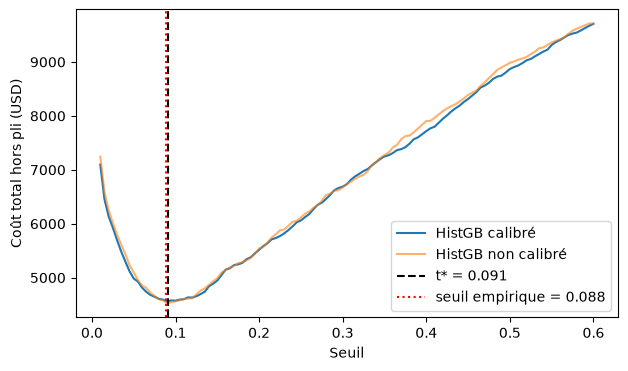

Seuil de coût minimal sur la grille (hors pli) : 0.09


In [10]:
grille = np.linspace(0.01, 0.6, 119)
couts = [cout_total(y_train, (p_cal >= s).astype(int)) for s in grille]
couts_brut = [cout_total(y_train, (p["HistGB réglé"] >= s).astype(int)) for s in grille]
plt.figure(figsize=(7, 4))
plt.plot(grille, couts, label="HistGB calibré")
plt.plot(grille, couts_brut, label="HistGB non calibré", alpha=0.6)
plt.axvline(t_star, color="k", ls="--", label=f"t* = {t_star:.3f}")
plt.axvline(t_emp, color="red", ls=":", label=f"seuil empirique = {t_emp:.3f}")
plt.xlabel("Seuil"); plt.ylabel("Coût total hors pli (USD)"); plt.legend()
plt.savefig(FIGURES / "05_cout_seuil.png", dpi=120, bbox_inches="tight"); plt.show()
print("Seuil de coût minimal sur la grille (hors pli) :", round(grille[int(np.argmin(couts))], 3))

Q9.1 — Sur le train (18 819 personnes, 2 650 bancarisées) :

| Seuil | TN | FP | FN | TP | Contactés | Coût |
|---|---|---|---|---|---|---|
| 0,5 | 15 762 | 407 | 1 733 | 917 | 1 324 | 8 868,5 USD |
| t* = 0,091 | 11 027 | 5 142 | 396 | 2 254 | 7 396 | 4 551,0 USD |

Au seuil 0,5, on oublie 65 % des clients. Au seuil t*, on contacte plus de monde mais on n'oublie que 15 % des clients. KaziPay économise 4 317,5 USD (−49 %).

Q9.2 — Oui. Le seuil trouvé par `TunedThresholdClassifierCV` est 0,0885, très proche du seuil théorique 0,0909, et les coûts sont presque les mêmes. Ça montre que les probabilités sont bien calibrées. Je garde t* = 0,0909.

Q9.3 — Sans modèle :
- contacter tout le monde : 8 084,5 USD ;
- ne contacter personne : 13 250 USD.

Le modèle au seuil t* coûte 4 551 USD : il fait mieux que les deux (44 % moins cher que tout contacter). Au seuil 0,5, le modèle fait même pire que tout contacter : il faut choisir le bon seuil.

Q9.4 · Si $C_{FN}$ passe à 2 USD

In [11]:
t2 = seuil_theorique(c_fn=2)
comp = pd.DataFrame([resume_seuil(p_cal, t_star), resume_seuil(p_cal, t2, c_fn=2)],
                    index=["C_FN = 5", "C_FN = 2"])
comp.loc["C_FN = 2", "coût tout le monde"] = (n - n_pos) * COST_FP
comp.loc["C_FN = 2", "coût personne"] = n_pos * 2
comp

,seuil,TN,FP,FN,TP,contactés,coût (USD),coût tout le monde,coût personne
C_FN = 5,0.0909,11027,5142,396,2254,7396,4551.0,NaN,NaN
C_FN = 2,0.2000,14027,2142,889,1761,3903,2849.0,8084.5,5300.0


Q9.4 — Si $C_{FN} = 2$ USD, $t^* = 0{,}20$. On contacte presque deux fois moins de monde (3 903 au lieu de 7 396) : on accepte plus d'oublis car ils coûtent moins cher. Le coût est 2 849 USD, toujours mieux que « personne » (5 300) ou « tout le monde » (8 084,5). Pas besoin de réentraîner, il suffit de changer le seuil.

In [12]:
# Décisions transmises au notebook 06
seuil_retenu = t_star
dec.update({"calibration": methode, "seuil_retenu": seuil_retenu, "seuil_empirique": t_emp,
            "cv_pr_auc_calibre": float(average_precision_score(y_train, p_cal)),
            "cv_pr_auc_calibre_plis": [float(average_precision_score(y_train.iloc[va], p_cal[va]))
                                       for _, va in cv.split(X_train, y_train)]})
DECISIONS.write_text(json.dumps(dec, indent=2))
dec

{'rf_min_samples_leaf': 50,
 'histgb_defaut_pr_auc': [0.5678159814594989, 0.028421765960187053],
 'histgb_params': {'learning_rate': 0.07373313352383347,
  'max_leaf_nodes': 7,
  'min_samples_leaf': 6,
  'l2_regularization': 7.684598675918744,
  'max_features': 0.9931252816724722,
  'max_iter': 327},
 'histgb_params_source': 'Optuna',
 'histgb_tuned_pr_auc': 0.5792285425734477,
 'calibration': 'sigmoid',
 'seuil_retenu': 0.09090909090909091,
 'seuil_empirique': 0.08845778171100854,
 'cv_pr_auc_calibre': 0.5768404112269002,
 'cv_pr_auc_calibre_plis': [0.5697186137271842,
  0.6010473703672233,
  0.5922191306803154,
  0.5332626170807749,
  0.593411502166305]}